In [83]:
%cd data/


[Errno 2] No such file or directory: 'data/'
/home/sm/experiments/data


/home/sm/experiments/.venv/lib/python3.9/site-packages/IPython/core/magics/osm.py:393: UserWarning: using bookmarks requires you to install the `pickleshare` library.
  bkms = self.shell.db.get('bookmarks', {})


In [99]:
#### data Reuse #########
import pandas as pd


step_reuse_base = {
    "baseline": "./data-reuse_2026_02_17_13_52_37_49a6924a/data",
    "two-sub-pipeline": "./data-reuse_2026_02_18_13_04_12_2fa8beab/data",   ## data-reuse_2026_02_17_13_39_37_539db030
    "three-sub-pipeline": "./data-reuse_2026_02_18_12_51_52_cd317c4f/data" ##"./data-reuse_2026_02_17_11_38_18_8d9dc1aa/data"
    ## data-reuse_2026_02_17_15_27_58_4caa049e -- > two nodes
    ## data-reuse_2026_02_18_12_51_52_cd317c4f  ---> one node

    
    
}

def compare(metric_name, p_name="pod", *args):
    all_agg = None
    
    for name, base_path in step_reuse_base.items():
        path = f"{base_path}/{metric_name}.csv"
        df = pd.read_csv(path)
        

        df["timestamp"] = pd.to_datetime(df["timestamp"])
        

        # Exclude prime-service pods 
        df = df[~df[p_name].astype(str).str.startswith("prime-service")]
        
        # Compute duration
        duration = (df["timestamp"].max() - df["timestamp"].min()).total_seconds()
        
        df["type"] = name
        df["duration"] = duration
        

        if all_agg is None:
            all_agg = df
        else:
            all_agg = pd.concat([all_agg, df], ignore_index=True)
    

    all_agg["pod"] = all_agg[p_name].astype(str)
    

    durations = all_agg.groupby("type")["duration"].first().reset_index()
    
    def counter_increase(x):
        x = x.sort_values()
        diff = x.diff()
        diff[diff < 0] = 0
        return diff.sum()
        
    metric_per_pod = (
        all_agg
        .groupby(["type", "pod"]+list(args))[metric_name]
#        .agg(lambda x: x.max() - x.min())
        .agg(counter_increase)   
        .reset_index()
    )
    

    total_per_setup = (
        metric_per_pod
        .groupby(["type"]+list(args))[metric_name]
        .sum()
        .reset_index()
    )

        
    return total_per_setup, durations


In [97]:
totals, durations = compare("system_cpu_usage_raw", "pod")
print(totals)
print("-------")
print(durations)

                 type  system_cpu_usage_raw
0            baseline            515.638216
1  three-sub-pipeline            273.399317
2    two-sub-pipeline            266.745500
-------
                 type  duration
0            baseline     660.0
1  three-sub-pipeline     380.0
2    two-sub-pipeline     640.0


In [86]:
totals, durations = compare("kepler_node_cpu_power_raw", "node_name")
print(totals)

                 type  kepler_node_cpu_power_raw
0            baseline              175929.199024
1  three-sub-pipeline               85245.734669
2    two-sub-pipeline               73406.004284


In [94]:
totals, durations = compare("pod_network_receive_bytes_raw", "pod")
display(totals)
totals, durations = compare("pod_network_transmit_bytes_raw", "pod")
display(totals)

,type,pod_network_receive_bytes_raw
0,baseline,82918.0
1,three-sub-pipeline,56765.0
2,two-sub-pipeline,50823.0


,type,pod_network_transmit_bytes_raw
0,baseline,78861.0
1,three-sub-pipeline,50003.0
2,two-sub-pipeline,50137.0


In [107]:
totals, durations = compare("node_network_receive_bytes", "node","node","device") # add device filtering
display(totals[(totals["node"] == "sm-gpu") & (totals["device"] == "enp9s0")])
totals, durations = compare("node_network_transmit_bytes", "node","node","device") # add device filtering
display(totals[(totals["node"] == "sm-gpu") & (totals["device"] == "enp9s0")])

,type,node,device,node_network_receive_bytes
97,baseline,sm-gpu,enp9s0,27203654.0
236,three-sub-pipeline,sm-gpu,enp9s0,16256544.0
370,two-sub-pipeline,sm-gpu,enp9s0,20670441.0


,type,node,device,node_network_transmit_bytes
97,baseline,sm-gpu,enp9s0,201867485.0
236,three-sub-pipeline,sm-gpu,enp9s0,128197783.0
370,two-sub-pipeline,sm-gpu,enp9s0,208869371.0


In [108]:
totals, durations = compare("pod_fs_reads_bytes", "pod")
display(totals)
totals, durations = compare("pod_fs_write_bytes", "pod")
display(totals)


,type,pod_fs_reads_bytes
0,baseline,597323776.0
1,three-sub-pipeline,21852160.0
2,two-sub-pipeline,4096.0


,type,pod_fs_write_bytes
0,baseline,492937216.0
1,three-sub-pipeline,164384768.0
2,two-sub-pipeline,147456.0


In [45]:
totals, durations = compare("pod_memory_usage","pod")
print(totals)

                 type  pod_memory_usage
0            baseline      4.666188e+09
1  three-sub-pipeline      3.277447e+09
2    two-sub-pipeline      3.168510e+09


In [122]:
totals, durations = compare("kepler_pod_cpu_power_joules_raw","pod_name", "pod_id")
display(totals.groupby("type")["kepler_pod_cpu_power_joules_raw"].sum().reset_index())
totals, durations = compare("kepler_pod_cpu_power_joules_raw", "pod_id")

totals, durations = compare("kepler_pod_cpu_power_joules_raw","pod_name","pod_id", "node")
display(totals.groupby(["type","node"])["kepler_pod_cpu_power_joules_raw"].sum().reset_index())

,type,kepler_pod_cpu_power_joules_raw
0,baseline,969.871879
1,three-sub-pipeline,696.734891
2,two-sub-pipeline,561.790649


,type,node,kepler_pod_cpu_power_joules_raw
0,baseline,sm-gpu,969.871879
1,three-sub-pipeline,sm-gpu,696.734891
2,two-sub-pipeline,sm-gpu,561.790649


In [123]:
import pandas as pd


step_reuse_base = {
    "4-step_reuse_0_stress": "./prime-service_2026_02_12_13_52_29_dcba7ac2/data",
    "full_reuse_0_stress": "./prime-service_2026_02_12_15_40_36_e0664c9f/data",
    "base_line_0_stress": "./prime-service_2026_02_12_14_48_51_9851aef1/data"
}

def compare(metric_name, p_name="pod"):
    all_agg = None
    
    for name, base_path in step_reuse_base.items():
        path = f"{base_path}/{metric_name}.csv"
        df = pd.read_csv(path)
        

        df["timestamp"] = pd.to_datetime(df["timestamp"])
        

        if name == "base_line_0_stress":
            df = df[~df[p_name].astype(str).str.startswith("prime-service")]
        
        # Compute duration
        duration = (df["timestamp"].max() - df["timestamp"].min()).total_seconds()
        
        df["type"] = name
        df["duration"] = duration
        

        if all_agg is None:
            all_agg = df
        else:
            all_agg = pd.concat([all_agg, df], ignore_index=True)
    

    all_agg["pod"] = all_agg[p_name].astype(str)
    

    durations = all_agg.groupby("type")["duration"].first().reset_index()
    

    metric_per_pod = (
        all_agg
        .groupby(["type", "pod"])[metric_name]
        .agg(lambda x: x.max() - x.min())
        .reset_index()
    )
    

    total_per_setup = (
        metric_per_pod
        .groupby("type")[metric_name]
        .sum()
        .reset_index()
    )

        
    return total_per_setup, durations

In [48]:
totals, durations = compare("system_cpu_usage_raw", "pod")
print(totals)
print("-------")
print(durations)

                    type  system_cpu_usage_raw
0  4-step_reuse_0_stress            938.624164
1     base_line_0_stress           1153.751494
2    full_reuse_0_stress           1634.720569
-------
                    type  duration
0  4-step_reuse_0_stress    1030.0
1     base_line_0_stress    1030.0
2    full_reuse_0_stress    1200.0


In [49]:
totals, durations = compare("kepler_node_cpu_power_raw", "node_name")
print(totals)

                    type  kepler_node_cpu_power_raw
0  4-step_reuse_0_stress              142247.409489
1     base_line_0_stress              145563.719630
2    full_reuse_0_stress              213345.700232


In [50]:
totals, durations = compare("pod_network_receive_bytes_raw", "pod")
print(totals)

                    type  pod_network_receive_bytes_raw
0  4-step_reuse_0_stress                          45032
1     base_line_0_stress                          43935
2    full_reuse_0_stress                          65966


In [51]:
totals, durations = compare("pod_network_transmit_bytes_raw", "pod")
print(totals)

                    type  pod_network_transmit_bytes_raw
0  4-step_reuse_0_stress                           33047
1     base_line_0_stress                           29073
2    full_reuse_0_stress                           43606


In [52]:
totals, durations = compare("kepler_pod_cpu_power_joules_raw","pod_name")
print(totals)

                    type  kepler_pod_cpu_power_joules_raw
0  4-step_reuse_0_stress                     11741.891084
1    full_reuse_0_stress                     40563.868595


In [53]:
totals, durations = compare("wall_power","node")
print(totals)

                    type  wall_power
0  4-step_reuse_0_stress         8.3
1     base_line_0_stress        24.3
2    full_reuse_0_stress        27.1


In [54]:
totals, durations = compare("pod_memory_usage","pod")
print(totals)

                    type  pod_memory_usage
0  4-step_reuse_0_stress         142671872
1     base_line_0_stress         174395392
2    full_reuse_0_stress         140599296


In [55]:
import pandas as pd


step_reuse_base = {
    "4-step_reuse_50_stress": "./prime-service_2026_02_12_14_27_07_efca3277/data",
    "full_reuse_50_stress": "./prime-service_2026_02_12_16_18_07_202e4981/data",
    "base_line_50_stress": "./prime-service_2026_02_12_15_23_20_8fb47d13/data",
}

def compare(metric_name, p_name="pod"):
    all_agg = None
    
    for name, base_path in step_reuse_base.items():
        path = f"{base_path}/{metric_name}.csv"
        df = pd.read_csv(path)
        

        df["timestamp"] = pd.to_datetime(df["timestamp"])
        

        if name == "base_line_0_stress":
            df = df[~df[p_name].astype(str).str.startswith("prime-service")]
        
        # Compute duration
        duration = (df["timestamp"].max() - df["timestamp"].min()).total_seconds()
        
        df["type"] = name
        df["duration"] = duration
        

        if all_agg is None:
            all_agg = df
        else:
            all_agg = pd.concat([all_agg, df], ignore_index=True)
    

    all_agg["pod"] = all_agg[p_name].astype(str)
    

    durations = all_agg.groupby("type")["duration"].first().reset_index()
    

    metric_per_pod = (
        all_agg
        .groupby(["type", "pod"])[metric_name]
        .agg(lambda x: x.max() - x.min())
        .reset_index()
    )
    

    total_per_setup = (
        metric_per_pod
        .groupby("type")[metric_name]
        .sum()
        .reset_index()
    )
    
    return total_per_setup, durations

In [56]:
totals, durations = compare("pod_network_transmit_bytes_raw", "pod")
print(totals)

                     type  pod_network_transmit_bytes_raw
0  4-step_reuse_50_stress                          120199
1     base_line_50_stress                          109452
2    full_reuse_50_stress                          128015


In [57]:
totals, durations = compare("pod_network_receive_bytes_raw", "pod")
print(totals)

                     type  pod_network_receive_bytes_raw
0  4-step_reuse_50_stress                         169865
1     base_line_50_stress                         157732
2    full_reuse_50_stress                         217212


In [58]:
totals, durations = compare("kepler_node_cpu_power_raw", "node_name")
print(totals)

                     type  kepler_node_cpu_power_raw
0  4-step_reuse_50_stress              174845.645164
1     base_line_50_stress              297618.267547
2    full_reuse_50_stress               98959.424339


In [59]:
totals, durations = compare("system_cpu_usage_raw", "pod")
print(totals)

                     type  system_cpu_usage_raw
0  4-step_reuse_50_stress           2071.156043
1     base_line_50_stress           2438.144892
2    full_reuse_50_stress           1582.550749


In [60]:
totals, durations = compare("kepler_pod_cpu_power_joules_raw","pod_name")
print(totals)

                     type  kepler_pod_cpu_power_joules_raw
0  4-step_reuse_50_stress                     23352.091491
1     base_line_50_stress                     34757.486164
2    full_reuse_50_stress                     55040.485407


In [61]:
totals, durations = compare("wall_power","node")
print(totals)

                     type  wall_power
0  4-step_reuse_50_stress         7.5
1     base_line_50_stress        25.4
2    full_reuse_50_stress        25.3


In [62]:
totals, durations = compare("pod_memory_usage","pod")
print(totals)

                     type  pod_memory_usage
0  4-step_reuse_50_stress         174288896
1     base_line_50_stress         192700416
2    full_reuse_50_stress         156303360


In [63]:
import pandas as pd
totals, durations = compare("pod_network_transmit_bytes_raw", "pod")
print(totals)

step_reuse_base = {
    "full_0_stress": "./prime-service_2026_02_12_15_40_36_e0664c9f/data",
    "full_5_stress": "./prime-service_2026_02_12_16_00_42_4146d3bc/data",
    "full_50_stress": "./prime-service_2026_02_12_16_18_07_202e4981/data",
}

# step_reuse_base = {
#     "baseline_0_stress": "./prime-service_2026_02_12_14_48_51_9851aef1/data",
#     "baseline_5_stress": "./prime-service_2026_02_12_15_06_08_993ee835/data",
#     "baseline_50_stress": "./prime-service_2026_02_12_15_23_20_8fb47d13/data",
# }

# step_reuse_base = {
#     "4-reuse_0_stress": "./prime-service_2026_02_12_13_52_29_dcba7ac2/data",
#     "4-reuse_5_stress": "./prime-service_2026_02_12_14_09_44_a15c409d/data",
#     "4-reuse_50_stress": "./prime-service_2026_02_12_14_27_07_efca3277/data",
# }

def compare(metric_name, p_name="pod"):
    all_agg = None
    
    for name, base_path in step_reuse_base.items():
        path = f"{base_path}/{metric_name}.csv"
        df = pd.read_csv(path)
        

        df["timestamp"] = pd.to_datetime(df["timestamp"])
        

        if name == "base_line_0_stress":
            df = df[~df[p_name].astype(str).str.startswith("prime-service")]
        
        # Compute duration
        duration = (df["timestamp"].max() - df["timestamp"].min()).total_seconds()
        
        df["type"] = name
        df["duration"] = duration
        

        if all_agg is None:
            all_agg = df
        else:
            all_agg = pd.concat([all_agg, df], ignore_index=True)
    

    all_agg["pod"] = all_agg[p_name].astype(str)
    

    durations = all_agg.groupby("type")["duration"].first().reset_index()
    

    metric_per_pod = (
        all_agg
        .groupby(["type", "pod"])[metric_name]
        .agg(lambda x: x.max() - x.min())
        .reset_index()
    )
    

    total_per_setup = (
        metric_per_pod
        .groupby("type")[metric_name]
        .sum()
        .reset_index()
    )
    
    return total_per_setup, durations

                     type  pod_network_transmit_bytes_raw
0  4-step_reuse_50_stress                          120199
1     base_line_50_stress                          109452
2    full_reuse_50_stress                          128015


In [64]:
totals, durations = compare("pod_network_transmit_bytes_raw", "pod")
print(totals)

             type  pod_network_transmit_bytes_raw
0   full_0_stress                           43606
1  full_50_stress                          128015
2   full_5_stress                           49752


In [65]:
totals, durations = compare("pod_network_receive_bytes_raw", "pod")
print(totals)

             type  pod_network_receive_bytes_raw
0   full_0_stress                          65966
1  full_50_stress                         217212
2   full_5_stress                          80822


In [66]:
totals, durations = compare("kepler_node_cpu_power_raw", "node_name")
print(totals)

             type  kepler_node_cpu_power_raw
0   full_0_stress              213345.700232
1  full_50_stress               98959.424339
2   full_5_stress              179532.402328


In [67]:
totals, durations = compare("system_cpu_usage_raw", "pod")
print(totals)

             type  system_cpu_usage_raw
0   full_0_stress           1634.720569
1  full_50_stress           1582.550749
2   full_5_stress           1026.812200


In [68]:
totals, durations = compare("kepler_pod_cpu_power_joules_raw","pod_name")
print(totals)

             type  kepler_pod_cpu_power_joules_raw
0   full_0_stress                     40563.868595
1  full_50_stress                     55040.485407
2   full_5_stress                     45929.363539


In [69]:
totals, durations = compare("wall_power","node")
print(totals)

             type  wall_power
0   full_0_stress        27.1
1  full_50_stress        25.3
2   full_5_stress        27.9


In [70]:
totals, durations = compare("pod_memory_usage","pod")
print(totals)

             type  pod_memory_usage
0   full_0_stress         140599296
1  full_50_stress         156303360
2   full_5_stress         147128320


In [71]:
totals, durations = compare_total("kepler_node_cpu_power_raw", "node_name")

plt.figure()
plt.bar(totals["type"], totals["kepler_node_cpu_power_raw"])
plt.xlabel("Experiment Type")
plt.ylabel("Total Power Consumption")
plt.title("Total Power Comparison")
plt.xticks(rotation=45)
plt.show()

NameError: name 'compare_total' is not defined

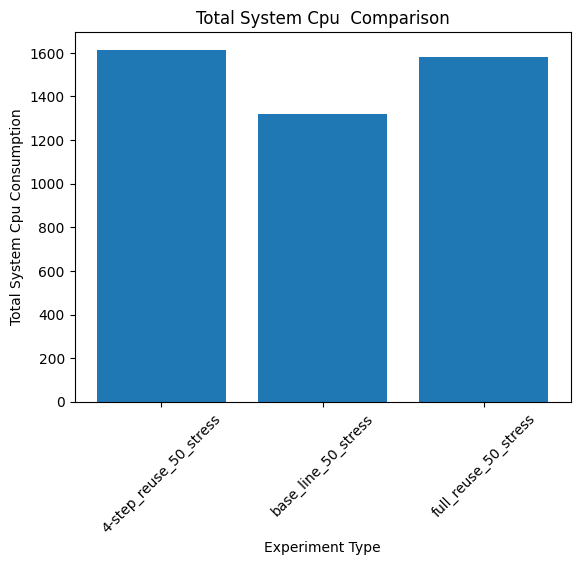

In [ ]:
totals, durations = compare_total("system_cpu_usage_raw", "pod")
plt.figure()
plt.bar(totals["type"], totals["system_cpu_usage_raw"])
plt.xlabel("Experiment Type")
plt.ylabel("Total System Cpu Consumption")
plt.title("Total System Cpu  Comparison")
plt.xticks(rotation=45)
plt.show()